# Data Visualization and Storytelling with Matplotlib & Seaborn

**Dataset:** Seaborn Tips Dataset &nbsp;|&nbsp; **Tools:** Python, Pandas, Matplotlib, Seaborn &nbsp;|&nbsp; **Project type:** Data visualization and exploratory analysis

---

## Table of Contents

1. Project Overview
2. Problem Statement
3. Project Objectives
4. Research Questions
5. Dataset Description
6. Importing Libraries
7. Loading the Dataset
8. Exploratory Data Analysis
9. Data Quality Assessment
10. Data Visualization and Analysis
    - 10.1 Histogram: Distribution of Total Restaurant Bills
    - 10.2 Box Plot: Distribution of Tips by Day
    - 10.3 Bar Chart: Average Tip Amount by Day
    - 10.4 Scatter Plot: Relationship Between Total Bill and Tip
    - 10.5 Correlation Heatmap: Relationships Between Numerical Variables
    - 10.6 Combined Visualization Dashboard
11. Key Findings and Insights
12. Conclusion
13. Limitations and Future Improvements

---

## 1. Project Overview

This notebook is the second project in my Data Analytics portfolio, following [Titanic EDA](https://github.com/BhoomikaJain21/Titanic-EDA). While the first project centred on exploratory data analysis with summary tables, this project focuses on **data visualization**: choosing suitable charts, labelling them clearly, reading them carefully and communicating what they show.

The analysis uses **Matplotlib** and **Seaborn** on the built-in Seaborn *Tips* dataset.

This is a **descriptive** analysis. It does not build predictive models, and it does not claim that any variable *caused* another to change.

---

## 2. Problem Statement

Tables of raw restaurant data are difficult to interpret at a glance. This project aims to explore how restaurant bills and tips are distributed, and how they relate to the other variables recorded in the dataset, using clear and well-labelled visualizations.

---

## 3. Project Objectives

- Inspect the structure, size and quality of the dataset before visualizing it.
- Show how total restaurant bills are distributed.
- Compare tip amounts across the days of the week.
- Examine the relationship between total bill and tip, distinguishing lunch from dinner.
- Measure the strength of the linear relationships between the numerical variables.
- Combine the main charts into one dashboard and save every chart as an image (150 DPI).
- Support every chart with a short takeaway that is backed by numbers, while keeping association separate from causation.

---

## 4. Research Questions

| # | Research Question | Main evidence in this notebook |
|---|---|---|
| 1 | How are total restaurant bills distributed? | Histogram (10.1) |
| 2 | How are tip amounts distributed? | Summary statistics (Section 8) and box plot by day (10.2) |
| 3 | How is the total bill related to the tip amount? | Scatter plot (10.4) and correlation heatmap (10.5) |
| 4 | Do bills or tips differ across day, meal time or party size? | Box plot and bar chart by day (10.2, 10.3), scatter plot coloured by meal time (10.4), heatmap including party size (10.5), supplementary tables (Section 11) |

> Question 4 is answered most directly for **day**. Meal time and party size are examined more lightly, as explained in Section 11.

---

## 5. Dataset Description

The **Tips** dataset is one of the sample datasets included with Seaborn. It contains **244 rows and 7 columns**, where each row records one restaurant bill along with the tip that was left.

| Column | Description | Data Type | Values |
|---|---|---|---|
| `total_bill` | Total bill amount in US dollars (USD) | Numerical (float) | 3.07 to 50.81 |
| `tip` | Tip amount in US dollars (USD) | Numerical (float) | 1.00 to 10.00 |
| `sex` | Sex of the person who paid the bill | Categorical | Male, Female |
| `smoker` | Whether the party included smokers | Categorical | Yes, No |
| `day` | Day of the week | Categorical | Thur, Fri, Sat, Sun |
| `time` | Meal time | Categorical | Lunch, Dinner |
| `size` | Number of people in the party | Numerical (integer) | 1 to 6 |

**Source:** loaded with `sns.load_dataset('tips')`. Seaborn downloads the data when this runs, so an internet connection is needed the first time.

---

## 6. Importing Libraries

Pandas handles the data, while Matplotlib and Seaborn create the charts. `pathlib.Path` (part of Python's standard library) is used to save the chart images in an `outputs/` folder.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

---

## 7. Loading the Dataset

In [ ]:
df = sns.load_dataset('tips')
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


---

## 8. Exploratory Data Analysis

Before creating any visualization, the dataset is inspected to understand its structure, size and basic statistics.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [ ]:
df.shape

(244, 7)

In [ ]:
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


### Key Observations from the Inspection

- The dataset has **244 rows and 7 columns**.
- Three columns are numerical (`total_bill`, `tip`, `size`) and four are categorical (`sex`, `smoker`, `day`, `time`).
- `total_bill` ranges from **3.07 to 50.81**, with a mean of about **19.79** and a median of about **17.80**.
- `tip` ranges from **1.00 to 10.00**, with a mean of about **3.00** and a median of **2.90**. The maximum is far above the 75th percentile (about 3.56), so a few large tips stretch the upper end.
- `size` ranges from **1 to 6**, with a median of **2**.

---

## 9. Data Quality Assessment

Two data quality checks were performed: missing values and duplicate records.

In [ ]:
df.isna().sum()

,0
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df[df.duplicated(keep=False)]

,total_bill,tip,sex,smoker,day,time,size
198,13.0,2.0,Female,Yes,Thur,Lunch,2
202,13.0,2.0,Female,Yes,Thur,Lunch,2


**Observation:** One pair of identical records was found, at index positions **198 and 202** (both: `total_bill` 13.0, `tip` 2.0, Female, smoker, Thursday, lunch, party size 2).

Both records were **retained**.

**Reasoning:** Identical values across all columns do not by themselves establish that the two rows describe the same transaction. The dataset has no transaction ID or timestamp that could confirm this, and two different parties could plausibly produce the same values. Removing one row could therefore discard a valid observation.

| Check | Result | Action Taken |
|---|---|---|
| Missing values | None in any column | No action needed |
| Duplicate records | 1 pair (rows 198 and 202) | Both retained; all 244 rows are used |

---

## 10. Data Visualization and Analysis

This section creates five individual charts and then combines four of them into a dashboard. All charts share the same theme: a white grid background, one primary blue (`#2E6F9E`), consistent fonts, USD labels on money axes and titles that state what the chart shows. Each chart is saved to the `outputs/` folder at **150 DPI**.

### Chart Theme and Output Folder

In [20]:
sns.set_theme(
    style='whitegrid',
    context='notebook',
    rc={
        'font.family': 'sans-serif',
        'axes.titleweight': 'bold',
        'axes.titlesize': 14,
        'axes.labelsize': 12,
        'figure.dpi': 100,      # on-screen size in the notebook
        'savefig.dpi': 150,     # resolution of the saved image files
    },
)
PRIMARY_COLOR = '#2E6F9E'

### 10.1 Histogram: Distribution of Total Restaurant Bills

**Objective:** Explore how restaurant bill amounts (`total_bill`) are distributed.

**Chart choice:** A histogram groups the values into equal-width intervals (*bins*) and counts how many bills fall into each one. This chart uses:

- **20 bins** for the histogram. The number of bins affects how detailed or smooth the shape appears.
- A **KDE (kernel density estimate)** curve, which draws a smooth estimate of the distribution over the bars.
- The **y-axis** shows the number of bills in each bin and the **x-axis** shows the bill amount in US dollars.

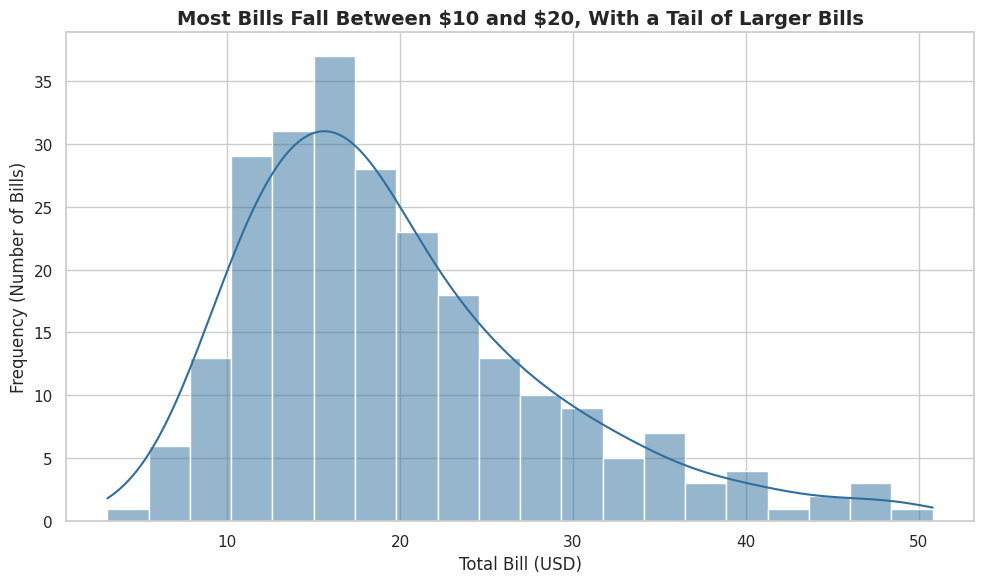

In [21]:
plt.figure(figsize=(10, 6))
sns.histplot(df['total_bill'], bins=20, kde=True, color=PRIMARY_COLOR)
plt.title(r'Most Bills Fall Between \$10 and \$20, With a Tail of Larger Bills',
          fontsize=14, fontweight='bold')
plt.xlabel('Total Bill (USD)')
plt.ylabel('Frequency (Number of Bills)')
plt.tight_layout()
plt.show()

In [22]:
# Numbers behind the takeaway
bill = df['total_bill']
print(f"Mean bill:   ${bill.mean():.2f}")
print(f"Median bill: ${bill.median():.3f}")
print(f"Skewness:    {bill.skew():.2f}")
print(f"Bills from $10 to $20: {bill.between(10, 20).sum()} of {len(bill)} ({bill.between(10, 20).mean():.1%})")
print(f"Bills below $25:       {(bill < 25).sum()} of {len(bill)} ({(bill < 25).mean():.1%})")
print(f"Bills of $40 or more:  {(bill >= 40).sum()} of {len(bill)}")

Mean bill:   $19.79
Median bill: $17.795
Skewness:    1.13
Bills from $10 to $20: 130 of 244 (53.3%)
Bills below $25:       188 of 244 (77.0%)
Bills of $40 or more:  10 of 244


> **Key Insight:** Restaurant bills are concentrated in the lower range: 130 of 244 bills (53.3%) are between \$10 and \$20, and 77.0% are below \$25. The distribution is **right-skewed** (skewness 1.13): the mean (about \$19.79) is above the median (about \$17.80) because a smaller number of high bills, up to \$50.81, stretch the upper tail. Only 10 bills are \$40 or more.


### 10.2 Box Plot: Distribution of Tips by Day

**Objective:** Compare how tip amounts are spread across the four days in the dataset.

**Chart choice:** A box plot summarises each day's tips with the **median** (line inside the box), the **interquartile range** (the box, covering the middle 50% of tips) and **whiskers**. Points beyond the whiskers are shown individually and are unusually large or small compared with that day's other tips.

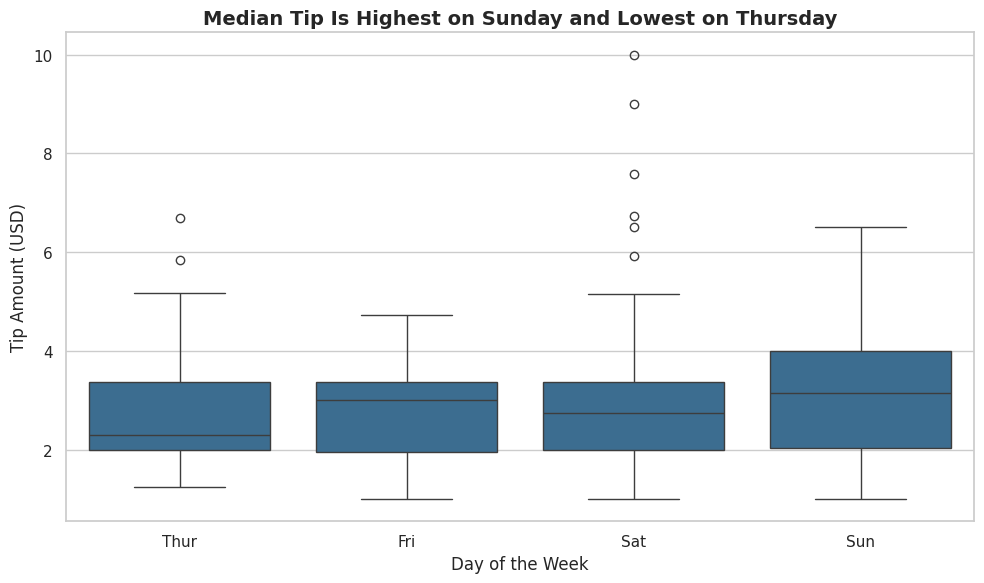

In [23]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='day', y='tip', color=PRIMARY_COLOR)
plt.title('Median Tip Is Highest on Sunday and Lowest on Thursday',
          fontsize=14, fontweight='bold')
plt.xlabel('Day of the Week')
plt.ylabel('Tip Amount (USD)')
plt.tight_layout()
plt.show()

In [24]:
# Numbers behind the takeaway: tip statistics for each day
df.groupby('day', observed=True)['tip'].agg(['count', 'mean', 'median', 'std', 'max']).round(3)

,count,mean,median,std,max
day,,,,,
Thur,62,2.771,2.305,1.240,6.70
Fri,19,2.735,3.000,1.020,4.73
Sat,87,2.993,2.750,1.631,10.00
Sun,76,3.255,3.150,1.235,6.50


In [25]:
# Context: how many bills of each meal time fall on each day
pd.crosstab(df['day'], df['time'])

time,Lunch,Dinner
day,,
Thur,61,1
Fri,7,12
Sat,0,87
Sun,0,76


> **Key Insight:** Tip amounts vary across the week. **Sunday** has the highest median tip (\$3.15) and **Thursday** the lowest (about \$2.31), with Saturday at \$2.75. Saturday has the widest spread (standard deviation 1.63) and contains the largest tip in the dataset (\$10.00). Friday's median (\$3.00) rests on only 19 bills, so it should be read cautiously.
>
> **Caution:** Day and meal time overlap heavily in this dataset. Thursday is almost entirely lunch (61 of 62 bills), while Saturday (87) and Sunday (76) are dinner only. The day-to-day differences therefore cannot be separated from lunch-versus-dinner differences, and these results describe patterns, not the effect of the day itself.

### 10.3 Bar Chart: Average Tip Amount by Day

**Objective:** Compare the **average (mean)** tip for each day in a single, easy-to-read view.

**Chart choice:** Each bar shows the mean tip for one day, with the value printed on the bar. The black lines are **95% confidence intervals**, which show how much uncertainty surrounds each average given the number of bills. (A fixed random seed makes these bootstrapped intervals identical on every run.)

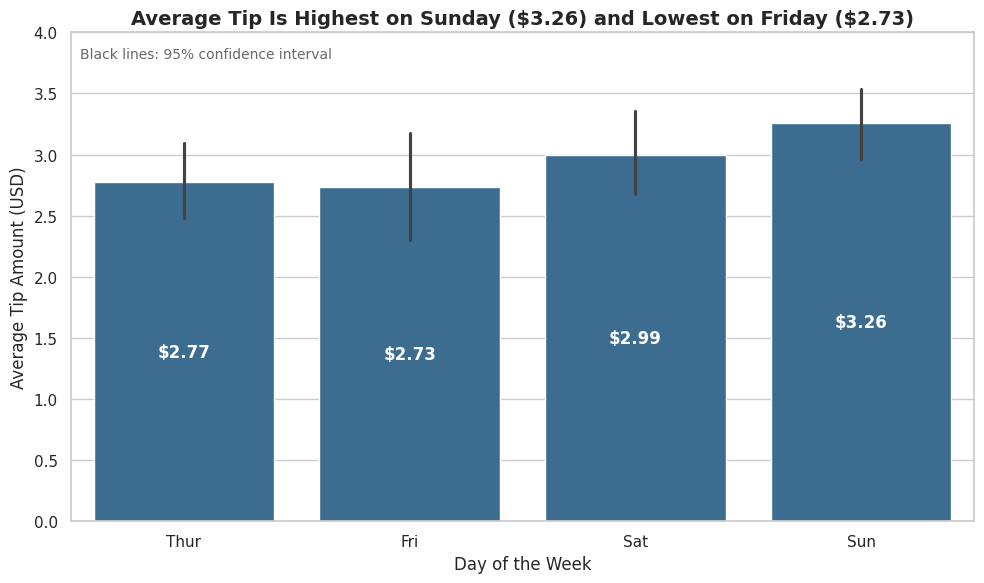

In [26]:
mean_tip = df.groupby('day', observed=True)['tip'].mean()

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df, x='day', y='tip', estimator='mean', color=PRIMARY_COLOR, seed=42)

# Print each day's average tip on its bar
for container in ax.containers:
    ax.bar_label(container, fmt='$%.2f', label_type='center',
                 color='white', fontweight='bold', fontsize=12)

# Short note explaining the black lines
ax.set_ylim(0, 4)
ax.text(0.01, 0.97, 'Black lines: 95% confidence interval',
        transform=ax.transAxes, ha='left', va='top', fontsize=10, color='dimgray')

plt.title(rf'Average Tip Is Highest on Sunday (\${mean_tip["Sun"]:.2f}) and Lowest on Friday (\${mean_tip["Fri"]:.2f})',
          fontsize=14, fontweight='bold')
plt.xlabel('Day of the Week')
plt.ylabel('Average Tip Amount (USD)')
plt.tight_layout()
plt.show()

> **Key Insight:** **Sunday** has the highest average tip (about \$3.26), followed by Saturday (about \$2.99), Thursday (about \$2.77) and Friday (about \$2.73), based on the group statistics in Section 10.2. The averages are close together and their confidence intervals overlap, so the chart shows modest differences rather than clear-cut gaps. Friday has the fewest bills (19), which makes its average the least certain.

### 10.4 Scatter Plot: Relationship Between Total Bill and Tip

**Objective:** Examine whether larger bills tend to come with larger tips, and whether lunch and dinner look different.

**Chart choice:** Each point is one bill. The x-axis shows the total bill and the y-axis the tip. Colour distinguishes **lunch** from **dinner**, and slight transparency (`alpha=0.8`) keeps overlapping points visible. The legend sits in the empty upper-left corner so that it does not hide any points.

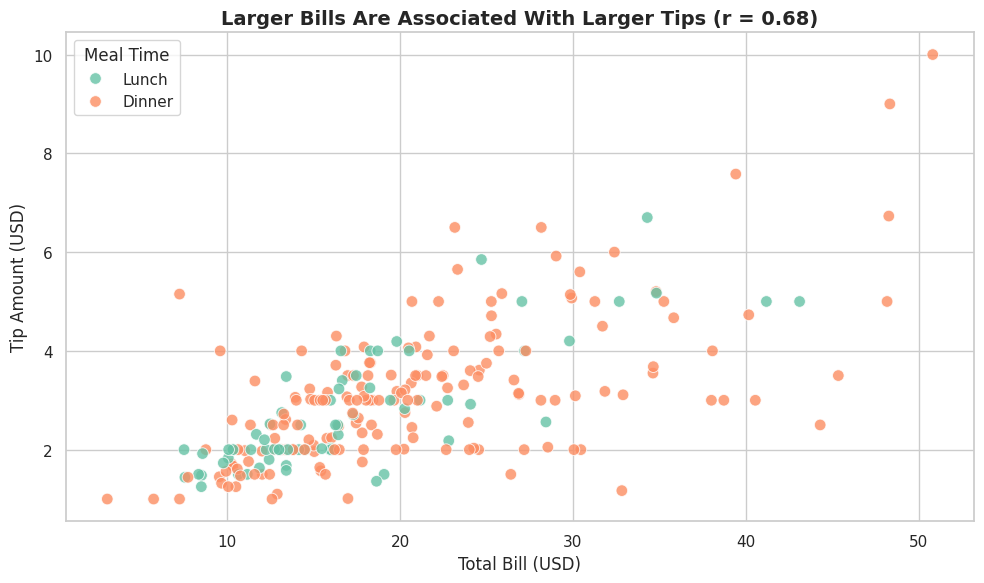

In [27]:
r_bill_tip = df['total_bill'].corr(df['tip'])

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='total_bill',
    y='tip',
    hue='time',
    palette='Set2',
    s=70,
    alpha=0.8
)
plt.title(f'Larger Bills Are Associated With Larger Tips (r = {r_bill_tip:.2f})',
          fontsize=14, fontweight='bold')
plt.xlabel('Total Bill (USD)')
plt.ylabel('Tip Amount (USD)')
plt.legend(title='Meal Time', loc='upper left')
plt.tight_layout()
plt.show()

In [28]:
# Numbers behind the takeaway
print(f"All bills: n = {len(df)}, correlation = {df['total_bill'].corr(df['tip']):.3f}")
for meal, group in df.groupby('time', observed=True):
    print(f"{meal}: n = {len(group)}, correlation = {group['total_bill'].corr(group['tip']):.3f}")

All bills: n = 244, correlation = 0.676
Lunch: n = 68, correlation = 0.805
Dinner: n = 176, correlation = 0.633


> **Key Insight:** Total bill and tip show a **positive association** (correlation 0.68 across all 244 bills): tips tend to be higher on larger bills, although the points are widely scattered, so tipping varies a lot between bills. The positive pattern appears within both meal times (about 0.81 for lunch and 0.63 for dinner). The highest point, a \$10.00 tip on a \$50.81 bill, stands apart from the main cloud.

### 10.5 Correlation Heatmap: Relationships Between Numerical Variables

**Objective:** Measure the strength of the linear relationships between the three numerical variables (`total_bill`, `tip`, `size`).

**Chart choice:** A heatmap displays the **Pearson correlation coefficient** for every pair of variables. Values run from -1 (perfect negative linear relationship) through 0 (no linear relationship) to +1 (perfect positive linear relationship). The colour scale is fixed to this full range so that colours can be compared fairly, and each cell is annotated with its value.

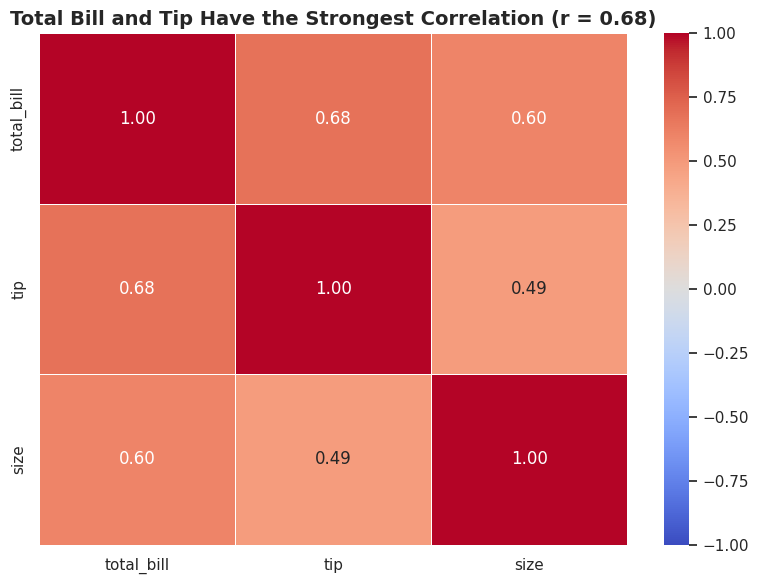

In [30]:
correlation_mat = df.select_dtypes(include='number').corr()
r_bill_tip = correlation_mat.loc['total_bill', 'tip']

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_mat,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(f'Total Bill and Tip Have the Strongest Correlation (r = {r_bill_tip:.2f})',
          fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

> **Key Insight:** Total bill and tip amount show the strongest positive correlation (approximately **0.68**). Party size is also positively correlated with both the total bill (about 0.60) and the tip (about 0.49). All three relationships are positive and moderate to fairly strong, and none is close to a perfect linear relationship.
>
> **Caution:** Correlation describes association only. It does not show that larger bills *cause* larger tips, and because party size, bill and tip all move together, this heatmap cannot separate their individual contributions.

### 10.6 Combined Visualization Dashboard

**Objective:** Bring the main findings together in one view.

**Layout:** a 2 × 2 grid with the bill histogram (top left), tips by day box plot (top right), bill-versus-tip scatter plot (bottom left) and correlation heatmap (bottom right). The bar chart is shown separately above because it presents the same day-level tip information as the box plot. The dashboard is saved as `outputs/tips_dashboard.png`.

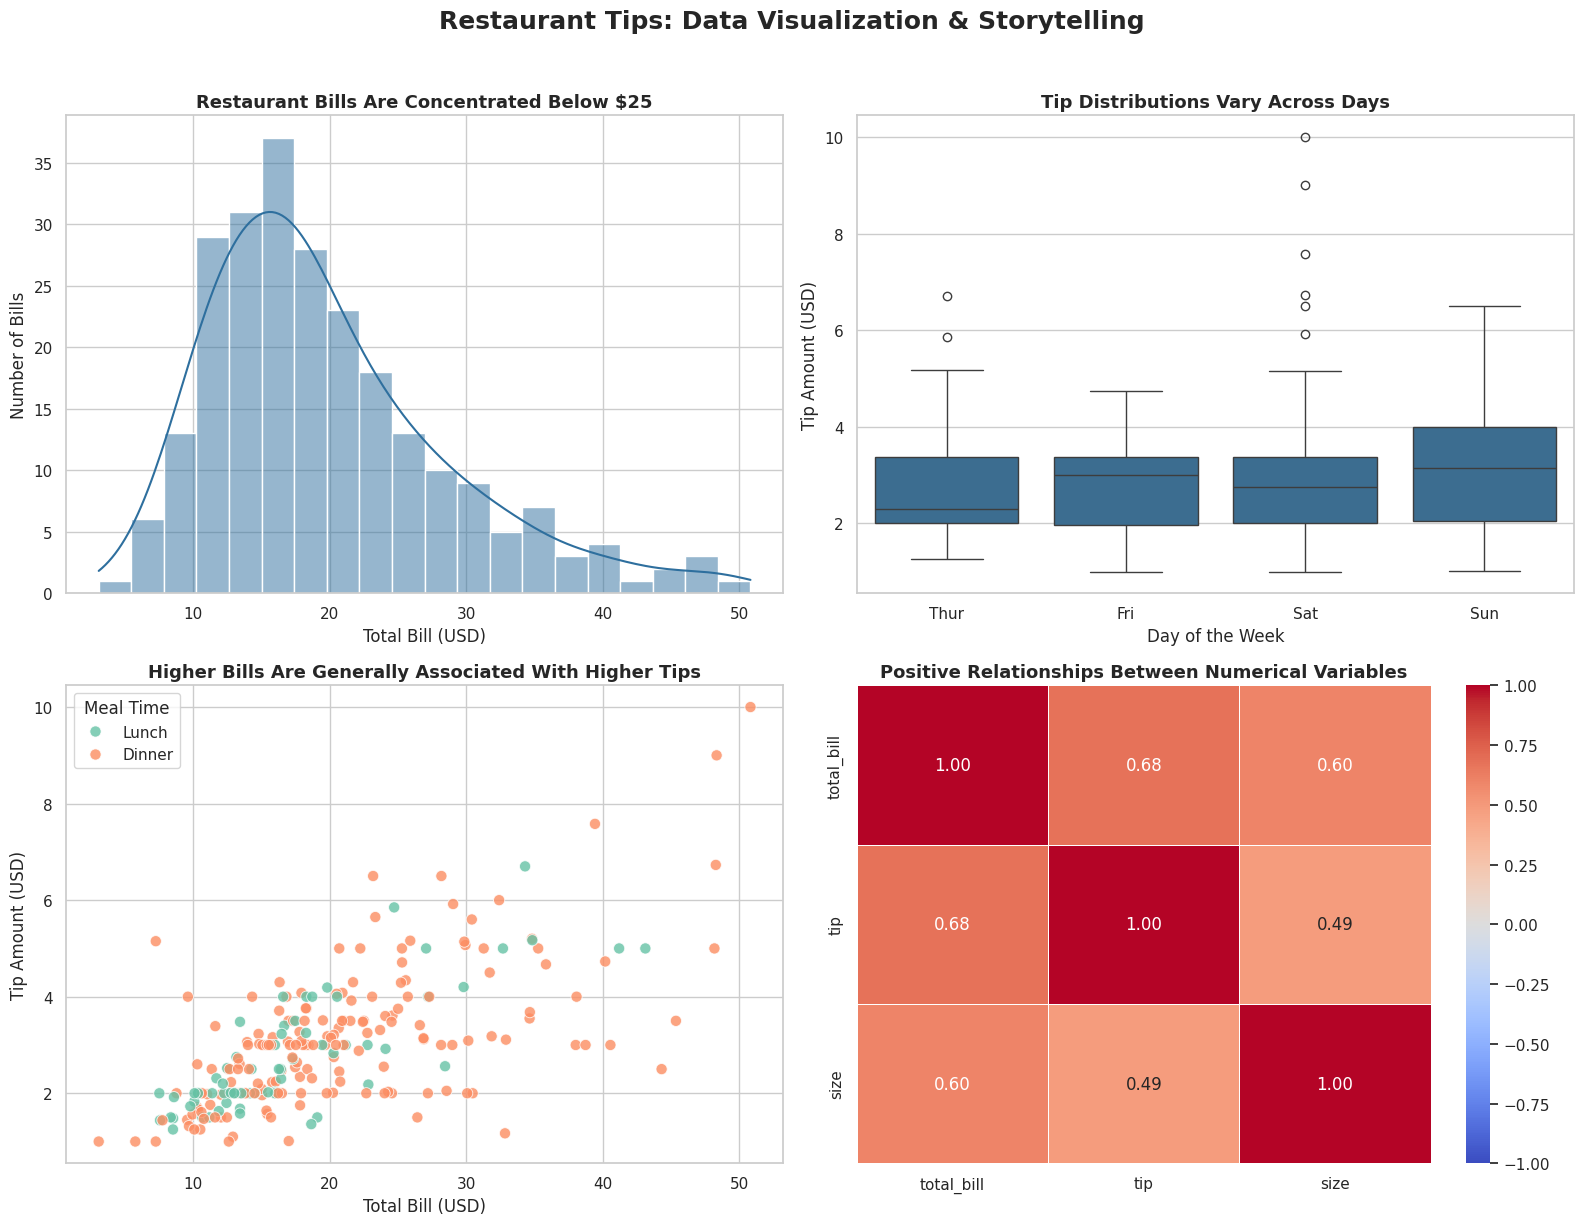

In [32]:
# Create a 2x2 dashboard

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram
sns.histplot(
    data=df,
    x='total_bill',
    bins=20,
    kde=True,
    color=PRIMARY_COLOR,
    ax=axes[0, 0]
)

axes[0, 0].set_title('Restaurant Bills Are Concentrated Below $25',
                     fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Total Bill (USD)')
axes[0, 0].set_ylabel('Number of Bills')


# 2. Box Plot
sns.boxplot(
    data=df,
    x='day',
    y='tip',
    color=PRIMARY_COLOR,
    ax=axes[0, 1]
)

axes[0, 1].set_title('Tip Distributions Vary Across Days',
                     fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Day of the Week')
axes[0, 1].set_ylabel('Tip Amount (USD)')


# 3. Scatter Plot
sns.scatterplot(
    data=df,
    x='total_bill',
    y='tip',
    hue='time',
    palette='Set2',
    s=65,
    alpha=0.8,
    ax=axes[1, 0]
)

axes[1, 0].set_title('Higher Bills Are Generally Associated With Higher Tips',
                     fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Total Bill (USD)')
axes[1, 0].set_ylabel('Tip Amount (USD)')
axes[1, 0].legend(title='Meal Time', loc='upper left')


# 4. Correlation Heatmap
sns.heatmap(
    correlation_mat,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[1, 1]
)

axes[1, 1].set_title('Positive Relationships Between Numerical Variables',
                     fontsize=13, fontweight='bold')


# Dashboard title and formatting
fig.suptitle(
    'Restaurant Tips: Data Visualization & Storytelling',
    fontsize=18,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()

plt.show()

> **Key Insight:** Read together, the four panels tell one story. Bills are mostly modest (77.0% are below \$25), tips vary by day with Sunday highest and Thursday lowest, larger bills are associated with larger tips (r = 0.68), and party size is positively correlated with both bill and tip. These are associations in 244 observations, not proof of cause and effect.

---

## 11. Key Findings and Insights

All figures below come directly from the outputs in this notebook.

### Supplementary summaries for Research Question 4

The charts above compare tips by **day** directly. To describe **meal time** and **party size** without adding new charts, the tables below summarise each group.

In [33]:
df.groupby('time', observed=True).agg(
    bills=('tip', 'size'),
    avg_bill=('total_bill', 'mean'),
    avg_tip=('tip', 'mean')
).round(2)

,bills,avg_bill,avg_tip
time,,,
Lunch,68,17.17,2.73
Dinner,176,20.80,3.10


In [34]:
df.groupby('size').agg(
    bills=('tip', 'size'),
    avg_bill=('total_bill', 'mean'),
    avg_tip=('tip', 'mean')
).round(2)

,bills,avg_bill,avg_tip
size,,,
1,4,7.24,1.44
2,156,16.45,2.58
3,38,23.28,3.39
4,37,28.61,4.14
5,5,30.07,4.03
6,4,34.83,5.22


### Findings by Research Question

| # | Research Question | Finding | Evidence |
|---|---|---|---|
| 1 | How are total restaurant bills distributed? | Right-skewed. Most bills are modest, with a tail of larger ones. | 53.3% of bills are \$10 to \$20; 77.0% are below \$25; mean about \$19.79 vs median about \$17.80; maximum \$50.81 |
| 2 | How are tip amounts distributed? | Tips are mostly small, with a few large values at the top end. | Range \$1.00 to \$10.00; median \$2.90; mean about \$3.00; 75th percentile about \$3.56 (Section 8). Tips differ by day (box plot) |
| 3 | How is the total bill related to the tip? | Positive association, moderately strong. | Correlation 0.68 (0.81 for lunch, 0.63 for dinner) |
| 4 | Do bills or tips differ across day, meal time or party size? | Yes, descriptively. All three show differences, but they overlap with each other and are not tested statistically. | **Day:** average tip from about \$2.73 (Fri) to \$3.26 (Sun). **Meal time:** dinner averages are higher than lunch (bill about \$20.80 vs \$17.17; tip about \$3.10 vs \$2.73). **Party size:** correlation 0.60 with bill and 0.49 with tip; average tip generally rises with party size (about \$1.44 at size 1 to about \$5.22 at size 6), though not at every step (size 5 is slightly below size 4), and sizes 1, 5 and 6 have only 4 to 5 bills each |

### Main Takeaways

1. **Most bills are modest.** Over half fall between \$10 and \$20, and only 10 of 244 are \$40 or more.
2. **Larger bills tend to come with larger tips.** The correlation is 0.68, and the pattern holds for both lunch and dinner.
3. **Sunday shows the highest average and median tip; Thursday shows the lowest median.** However, the average tips across days are close, their confidence intervals overlap, and the day groups differ in size.
4. **Day and meal time are tangled together.** Thursday is almost all lunch, while Saturday and Sunday are all dinner, so day differences and meal-time differences cannot be told apart here.
5. **Every relationship reported here is an association.** None of these results shows that one variable causes another.

---

## 12. Conclusion

This project used Matplotlib and Seaborn to turn a small restaurant dataset into a set of clear, labelled visualizations: a histogram, a box plot, a bar chart, a scatter plot, a correlation heatmap and a combined dashboard. The data was checked first: 244 rows, no missing values, and one pair of identical records (rows 198 and 202) that was kept because identical values do not prove the rows are the same transaction.

The charts show that bills are mostly modest and right-skewed, that tips tend to rise with the bill (correlation 0.68), and that tips differ modestly across days, with Sunday highest. The project also shows why careful reading matters: day and meal time overlap, some groups are small, and correlation is not causation.

---

## 13. Limitations and Future Improvements

### Limitations

- **Small sample:** 244 bills in total, and some groups are very small (for example, 19 bills on Friday, and 4 to 5 bills for party sizes 1, 5 and 6). Averages for these groups are unreliable.
- **Day and meal time overlap:** Thursday is almost all lunch and Saturday and Sunday are all dinner, so the effect of day cannot be separated from the effect of meal time.
- **Association, not causation:** this is observational data, and most comparisons look at one or two variables at a time.
- **Correlation limits:** Pearson correlation measures only *linear* association and can be influenced by unusual values such as the \$10.00 tip.
- **Descriptive methods only:** no significance tests were run, so differences between close averages may be due to chance. The only uncertainty shown is the confidence intervals on the bar chart.
- **Variables not visualized:** `sex` and `smoker` were not analysed, and `size` appears only in the correlation analysis and a summary table.
- **Limited background information:** the dataset has no dates, transaction IDs or details about the restaurant, so the results should not be generalised beyond this dataset.
- **Duplicate records retained:** results could differ slightly if rows 198 and 202 were treated as one record.

### Possible Future Improvements

- Analyse **tip as a percentage of the bill** to separate generosity from bill size.
- Add charts for `sex`, `smoker` and `size`, for example grouped bar charts or a facet grid by day and meal time.
- Add a regression line with a confidence band to the scatter plot, and fit a simple regression to quantify the relationship.
- Apply statistical tests (for example, a Kruskal-Wallis test across days) and report confidence intervals for group differences.
- Repeat the analysis without the duplicate row as a sensitivity check.
- Build interactive versions of the charts with a library such as Plotly.

---

**Author:** Bhoomika Jain &nbsp;|&nbsp; [GitHub](https://github.com/BhoomikaJain21)